# Quality assessment of the 3DEP survey checkpoint database (ver. 2.0)

*Consolidated Standardized Survey-Grade Checkpoints 3DEP 2004 to 2025*, ver. 2.0 (December 2025),
<https://doi.org/10.5066/P13NOW9E>, 145,299 checkpoints.

> Unfortunately this dataset does not contain an uncertainty estimate per checkpoint elevation and past studies have noted some errors in misclassified units (feet vs meters) [Stoker et al 2022]. This notebook is an attempt to quantify the quality of the dataset and identify any systematic errors that may be present.

This notebook documents what we found while using the database as ground truth for DEM accuracy work. It reads the checkpoints from the release GeoPackage and computes everything live (a few minutes: DEM samples, PROJ geoid and datum grids, three VDatum API calls).

| part | finding | rows |
|---|---|---:|
| 1 | heights with unit, decimal or datum errors, in 6 collections | 784 |
| 2 | heights that differ from re-running VDatum on the source fields by more than 2 cm | 477 |
| 3 | source coordinates inconsistent with their own `source_horizontal_epsg` | 4,748 |
| 4 | published lon,lat positions from non-NAD83(2011) sources that are re-labelled or of undetermined derivation, not transformed | 29,591 |
| 5 | example: how a lon,lat position error becomes a height error | 1 checkpoint |

Parts 1 and 5 compare each checkpoint with the source (OPR) DEM of the lidar project it was surveyed for. 

In theory the checkpoint `z_meter_vdatum_update` (or simply `z` in this notebook) is the in situ GPS-derived ground "truth" that should closely match the OPR DEM at the same point. In practice, the checkpoints may contain errors such as:
- Poor survey measurement
- Points with unit, decimal, or datum errors
- Points that have been re-labeled or transformed incorrectly from local UTM to lon,lat NAD83(2011)

In [1]:
import re, zipfile, urllib.parse
from pathlib import Path

import geopandas as gpd, matplotlib.pyplot as plt, numpy as np, pandas as pd
import pyproj, rasterio, requests

pyproj.network.set_network_enabled(True)   # for the Hawaii geoid grid
GDAL = dict(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif,.vrt",
            GDAL_HTTP_MULTIRANGE="YES", GDAL_HTTP_TIMEOUT="60", GDAL_HTTP_MAX_RETRY="3")
FT = 0.3048
cache = Path.home() / ".cache" / "3dep_checkpoints"; cache.mkdir(parents=True, exist_ok=True)

# 1. the checkpoints, from the release GeoPackage (23 MB zip, downloaded once)
ZIP = ("https://www.sciencebase.gov/catalog/file/get/67075e6bd34e969edc59c3e7"
       "?f=__disk__80%2F12%2F9e%2F80129e86d18461ed921b288f13e08c62e8590ffb")
zpath = cache / "Checkpoints_3DEP_2004_2025.zip"
if not zpath.exists():
    zpath.write_bytes(requests.get(ZIP, timeout=600).content)
gpkg = cache / "Checkpoints_3DEP_2004_2025.gpkg"
if not gpkg.exists():
    zipfile.ZipFile(zpath).extract(gpkg.name, cache)
PROJECTS = [12384, 58946, 191399, 11903, 1067, 4259]
allcp = gpd.read_file(gpkg).rename(columns={"unique_identifier": "id", "z_meter_vdatum_update": "z"})
cp = allcp[allcp.project_id.isin(PROJECTS)].copy()

# 2. each project's OPR work units, from WESM
wesm = pd.read_csv("https://prd-tnm.s3.amazonaws.com/StagedProducts/Elevation/metadata/WESM.csv",
                   usecols=["workunit", "project_id", "vert_crs", "sourcedem_link"])
wesm = wesm[wesm.project_id.isin(PROJECTS) & wesm.sourcedem_link.notna()]
print(len(cp), "checkpoints;", len(wesm), "OPR work units")

1022 checkpoints; 13 OPR work units


In [2]:
def opr_vrt(link, workunit):
    """A work unit's OPR DEM, read through its VRT (named after the WESM work unit)."""
    prefix = re.search(r"prefix=(.+)$", link).group(1).rstrip("/")
    return "/vsicurl/https://prd-tnm.s3.amazonaws.com/" + urllib.parse.quote(f"{prefix}/{workunit}.vrt")

def sample(path, lon, lat):
    """Raster values at lon/lat (NAD83(2011)) points, transformed into the raster's CRS."""
    with rasterio.Env(**GDAL), rasterio.open(path) as src:
        crs = pyproj.CRS(src.crs.to_wkt()); h = crs.sub_crs_list[0] if crs.is_compound else crs
        x, y = pyproj.Transformer.from_crs("EPSG:6318", h, always_xy=True).transform(lon, lat)
        l, b, r, t = src.bounds; inside = (x >= l) & (x <= r) & (y >= b) & (y <= t)
        v = np.full(len(x), np.nan)
        if inside.any():
            v[inside] = [s[0] for s in src.sample(zip(x[inside], y[inside]))]
        v[(v < -1e4) | (v > 1e5) | (v == (src.nodata if src.nodata is not None else np.nan))] = np.nan
    return v

def wesm_unit(label):
    """Metres per unit of a WESM vert_crs (EPSG code or text)."""
    try:
        return pyproj.CRS.from_epsg(int(label)).axis_info[0].unit_conversion_factor
    except (ValueError, pyproj.exceptions.CRSError):
        return 1.0 if "meter" in str(label).lower() else FT

# OPR DEM at every checkpoint (first work unit with a value), with the unit WESM gives it
cp["dem_raw"], cp["dem_label_unit"], cp["workunit"] = np.nan, np.nan, None
for _, wu in wesm.iterrows():
    todo = cp.index[(cp.project_id == wu.project_id) & cp.dem_raw.isna()]
    v = sample(opr_vrt(wu.sourcedem_link, wu.workunit), cp.geometry.x[todo].values, cp.geometry.y[todo].values)
    hit = todo[np.isfinite(v)]
    cp.loc[hit, "dem_raw"] = v[np.isfinite(v)]
    cp.loc[hit, ["dem_label_unit", "workunit"]] = wesm_unit(wu.vert_crs), wu.workunit
cp["dem"] = cp.dem_raw * cp.dem_label_unit            # DEM height in metres, as labelled

# independent check: Copernicus GLO-30 (metres, EGM2008)
def glo_tile(lon, lat):
    la, lo = int(np.floor(lat)), int(np.floor(lon))
    n = f"Copernicus_DSM_COG_10_N{la:02d}_00_W{-lo:03d}_00_DEM"
    return f"/vsicurl/https://copernicus-dem-30m.s3.amazonaws.com/{n}/{n}.tif"
cp["glo30"] = np.nan
for t, g in cp.groupby([glo_tile(x, y) for x, y in zip(cp.geometry.x, cp.geometry.y)]):
    with rasterio.Env(**GDAL), rasterio.open(t) as src:
        cp.loc[g.index, "glo30"] = [s[0] for s in src.sample(zip(g.geometry.x, g.geometry.y))]
print(cp.dem.notna().sum(), "of", len(cp), "checkpoints have an OPR DEM height")

957 of 1022 checkpoints have an OPR DEM height


In [3]:
def panel(ax, d, title, lines=(1, 1 / FT), hue=None, log=False):
    """Published checkpoint height vs DEM height, with GLO-30 behind."""
    ax.scatter(d.z, d.glo30, s=10, c="0.75", label="GLO-30 (independent)", zorder=1)
    groups = d.groupby(hue) if hue else [("OPR DEM", d)]
    for name, g in groups:
        ax.scatter(g.z, g.dem, s=12, label=name, zorder=2)
    lim = np.nanmax(np.r_[d.z, d.dem, d.glo30]) * 1.05
    lo = max(np.nanmin(np.r_[d.z, d.dem]) * 0.8, 0.5) if log else 0
    xs = np.array([lo, lim])
    for k in lines:
        ax.plot(xs, xs * k, "k--" if k == 1 else "r:", lw=1, zorder=0)
        at = 0.8 * lim if not log else lim ** 0.9 * lo ** 0.1   # 80% along the visible line
        ax.annotate("1:1" if k == 1 else f"×{k:.4g}", (at / max(k, 1), at * min(k, 1)),
                    fontsize=9, color="k" if k == 1 else "r", ha="left", va="top")
    if log:
        ax.set_xscale("log"); ax.set_yscale("log")
    ax.set(xlim=(lo, lim), ylim=(lo, lim), title=title,
           xlabel="published checkpoint height, z_meter_vdatum_update (m)", ylabel="DEM height (m)")
    ax.legend(fontsize=7, loc="lower right")

COLS = ["id", "point_type", "source_elevation", "source_vertical_unit", "z", "dem", "glo30"]
def examples(d, n=3):
    return d[COLS].dropna().head(n).round(2).set_index("id")

# Part 1. Heights with unit, decimal or datum errors

A **unit error multiplies** a height, while terrain change, vegetation and survey error only shift it, so the ratio `DEM / checkpoint`:  

*  ~1 for good points 
* ~3.2808 for metres converted as if feet
* ~0.3048 for feet treated as metres
* 10 or 100 for a misplaced decimal point. 

Every comparison also shows the independent Copernicus GLO-30 DEM (metres) at the same points, to rule out an issue with the OPR DEM.

| project_id | collection | rows | what is wrong |
|---:|---|---:|---|
| 12384 | CA_Sonoma_2013 | 411 | source heights are metres, labelled U.S. survey feet |
| 58946 | CA_Sacramento_2017 part of CA_Central_Valley_2016 (ids `*_58946_Sacramento*`) | 143 | same; the rest of the project is correct |
| 191399 | OR_HarneySilver_2020_A20, VVA points | 57 | metres labelled international feet; its NVA points are correct |
| 11903 | Fork_Salt_River_NRCS | 39 | feet labelled metres (the OPR DEM carries the same mislabel) |
| 1067 | ME_SouthernArea_2012 | 34 | decimal point misplaced: 19 points ×10, 15 points ×100 |
| 4259 | HI_Oahu_2012 | 100 | ellipsoid heights labelled NAVD88 (about 15.9 m too high) |

## 1.1 CA_Sonoma_2013 (project 12384): metres labelled U.S. survey feet

For all 411 checkpoints, the OPR DEM and GLO-30 both sit at ~ 3.28 × the checkpoint height. 

Thus `source_elevation` values are already metres, but are labelled
U.S. survey feet and were therefore incorrectly converted twice (×0.3048) to produce `z_meter_vdatum_update`. 

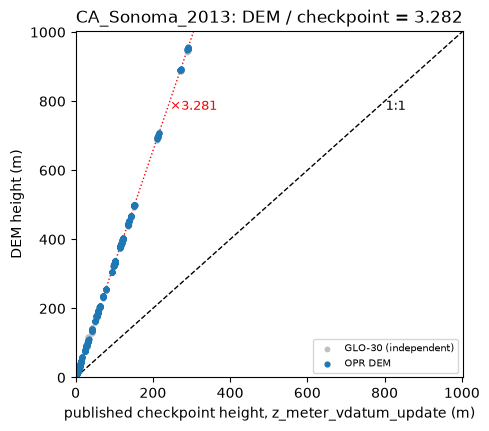

,point_type,source_elevation,source_vertical_unit,z,dem,glo30
id,,,,,,
Sonoma_County_CA_Lidar_12384_1,NVA,231.97,U.S. Survey Feet,70.69,231.99,231.61
Sonoma_County_CA_Lidar_12384_2,NVA,232.05,U.S. Survey Feet,70.72,232.07,231.61
Sonoma_County_CA_Lidar_12384_3,NVA,232.40,U.S. Survey Feet,70.82,232.40,233.67


In [4]:
d = cp[cp.project_id == 12384]
fig, ax = plt.subplots(figsize=(5, 4.5)); panel(ax, d, "CA_Sonoma_2013: DEM / checkpoint = %.3f" % (d.dem / d.z).median())
plt.show(); examples(d)

## 1.2 CA_Central_Valley_LiDAR_2016 (project 58946): the Sacramento subset

The same error in only part of a project: the 143 checkpoints with ids `*_58946_Sacramento*`
(surveyed 2017-02-02 to 02-12) read 3.28 × too low; the 165 `*_Central_Valley*` checkpoints in
the same project are correct. The Sacramento area is low-lying, so the absolute errors are
small (a few metres), but the ratio is the same.

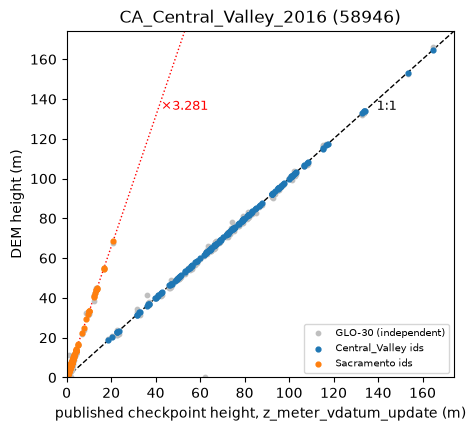

                        n  DEM / checkpoint
subset                                     
Central_Valley ids  165.0             1.000
Sacramento ids      143.0             3.299


,point_type,source_elevation,source_vertical_unit,z,dem,glo30
id,,,,,,
CA_Central_Valley_LiDAR_2016_D16_58946_Sacramento_2012,NVA,5.79,U.S. Survey Feet,1.76,5.79,5.28
CA_Central_Valley_LiDAR_2016_D16_58946_Sacramento_3033,VVA,3.44,U.S. Survey Feet,1.04,3.49,4.72
CA_Central_Valley_LiDAR_2016_D16_58946_Sacramento_3012,VVA,4.27,U.S. Survey Feet,1.30,4.35,3.46


In [5]:
d = cp[cp.project_id == 58946].assign(subset=lambda g: np.where(g.id.str.contains("_Sacramento"), "Sacramento ids", "Central_Valley ids"))
fig, ax = plt.subplots(figsize=(5, 4.5)); panel(ax, d, "CA_Central_Valley_2016 (58946)", hue="subset")
plt.show()
print(d.groupby("subset").apply(lambda g: pd.Series({"n": len(g), "DEM / checkpoint": (g.dem / g.z).median()})).round(3))
examples(d[d.subset == "Sacramento ids"])

## 1.3 OR_HarneySilver_2020_A20 (project 191399): the VVA points

The 57 VVA checkpoints (ids `_1` to `_57`) are labelled international feet but are metres: they
read 442 m where the ground is about 1,450 m. The 73 NVA checkpoints of the same survey are
correct.

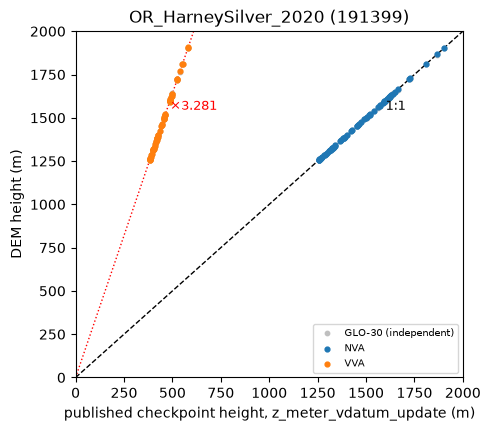

point_type
NVA    1.000
VVA    3.281
Name: DEM / checkpoint, dtype: float64


,point_type,source_elevation,source_vertical_unit,z,dem,glo30
id,,,,,,
OR_HarneySilver_2020_A20_191399_37,VVA,1464.69,International Feet,446.43,1464.82,1464.07
OR_HarneySilver_2020_A20_191399_55,VVA,1767.51,International Feet,538.71,1767.53,1766.77
OR_HarneySilver_2020_A20_191399_5,VVA,1366.29,International Feet,416.41,1366.23,1365.84


In [6]:
d = cp[cp.project_id == 191399]
fig, ax = plt.subplots(figsize=(5, 4.5)); panel(ax, d, "OR_HarneySilver_2020 (191399)", hue="point_type")
plt.show()
print(d.groupby("point_type").apply(lambda g: (g.dem / g.z).median()).round(3).rename("DEM / checkpoint"))
examples(d[d.point_type == "VVA"])

## 1.4 Fork_Salt_River_NRCS (project 11903): feet labelled metres, in the checkpoints *and* the DEM

The 39 checkpoints are labelled metres and read 784–865 m, higher than any point in Missouri
(Taum Sauk Mountain, 540 m). They are feet (`source_geoid` is `UNK`, so they were also never
VDatum-harmonized). The OPR DEM agrees with them only because **WESM labels the DEM metres
(`vert_crs` 5703) while its values are feet** too; GLO-30 reads 0.3048 × both.

The OPR DEM's mislabel is not a checkpoint problem; the screen catches such DEM labels
by checking every DEM's unit against GLO-30 before judging any checkpoint (78 more OPR work
units carry a wrong unit in WESM, all metre DEMs labelled feet).

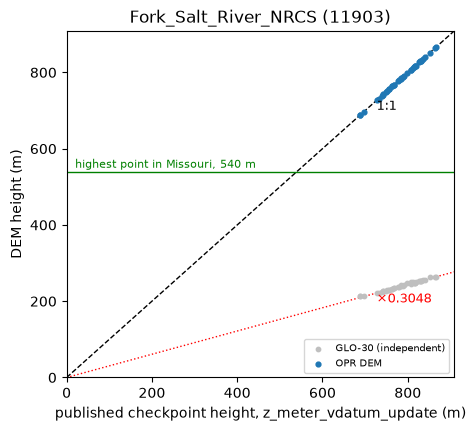

WESM vert_crs for the DEM: ['5703'] | GLO-30 / DEM = 0.3046


,point_type,source_elevation,source_vertical_unit,z,dem,glo30
id,,,,,,
Fork_Salt_River_NRCS_11903_1,Unknown,826.33,meter,826.33,826.23,252.61
Fork_Salt_River_NRCS_11903_2,Unknown,840.07,meter,840.07,839.96,255.66
Fork_Salt_River_NRCS_11903_3,Unknown,851.57,meter,851.57,851.29,263.18


In [7]:
d = cp[cp.project_id == 11903]
fig, ax = plt.subplots(figsize=(5, 4.5)); panel(ax, d, "Fork_Salt_River_NRCS (11903)", lines=(1, FT))
ax.axhline(540, color="g", lw=1); ax.annotate("highest point in Missouri, 540 m", (20, 550), color="g", fontsize=8)
plt.show()
print("WESM vert_crs for the DEM:", wesm[wesm.project_id == 11903].vert_crs.tolist(),
      "| GLO-30 / DEM = %.4f" % (d.glo30 / d.dem_raw).median())
examples(d)

## 1.5 ME_SouthernArea_2012 (project 1067): misplaced decimal point

Every one of the 34 `source_elevation` values lies between 1 and 10, as if the exponent of a
number in scientific notation had been dropped. Against the DEM, 19 points are 10 × too small
and 15 are 100 × too small (log axes).

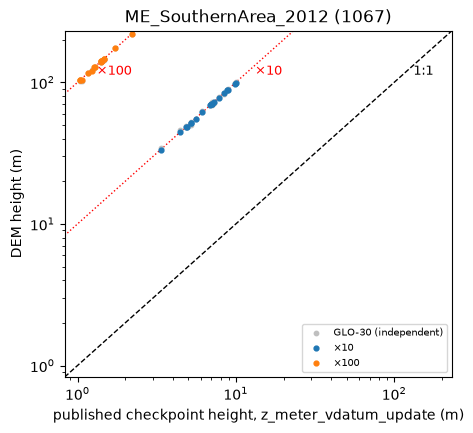

source_elevation range: 1.03183 - 9.9729
factor
×10     19
×100    15


,point_type,source_elevation,source_vertical_unit,z,dem,glo30
id,,,,,,
Maine_Midcoast_LiDAR_1067_1,Unknown,1.16,meter,1.16,116.53,115.68
Maine_Midcoast_LiDAR_1067_2,Unknown,6.15,meter,6.15,61.45,62.72
Maine_Midcoast_LiDAR_1067_3,Unknown,1.03,meter,1.07,103.20,102.84


In [8]:
d = cp[cp.project_id == 1067].assign(factor=lambda g: (10.0 ** np.round(np.log10(g.dem / g.z))).map("×{:g}".format))
fig, ax = plt.subplots(figsize=(5, 4.5)); panel(ax, d, "ME_SouthernArea_2012 (1067)", lines=(1, 10, 100), hue="factor", log=True)
plt.show()
print("source_elevation range:", d.source_elevation.min(), "-", d.source_elevation.max())
print(d.factor.value_counts().to_string())
examples(d)

## 1.6 HI_Oahu_2012 (project 4259): ellipsoid heights labelled NAVD88

Here the error is an offset, not a ratio: the checkpoints sit a nearly constant 15.9 m above the
project's DEM, about the geoid undulation on Oahu (GEOID12B, +15.3 m), so the heights look like
NAD83 ellipsoid heights. GLO-30 (a surface model, on EGM2008) confirms the offset, more loosely. (Hawaii also has no NAVD88; the WESM vertical
datum for this project is "Local Mean Sea Level in Meters".)

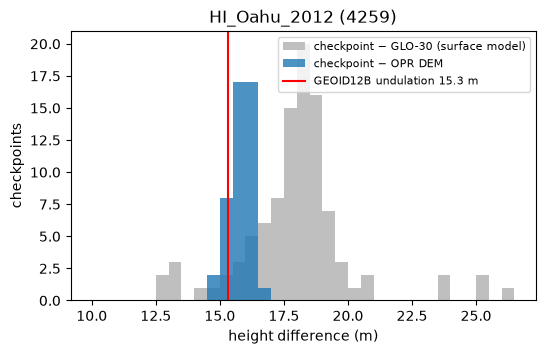

median checkpoint − DEM: 15.94 m (n=45)


,point_type,source_elevation,source_vertical_unit,z,dem,glo30
id,,,,,,
Oahu_HI_10m_NPS_LiDAR_4259_4,NVA,17.73,meter,17.73,2.68,0.20
Oahu_HI_10m_NPS_LiDAR_4259_5,NVA,17.93,meter,17.93,3.32,3.69
Oahu_HI_10m_NPS_LiDAR_4259_7,NVA,25.38,meter,25.38,9.53,6.01


In [9]:
d = cp[cp.project_id == 4259].copy()
g12b = pyproj.Transformer.from_pipeline(
    "+proj=pipeline +step +proj=axisswap +order=2,1 +step +proj=unitconvert +xy_in=deg +xy_out=rad "
    "+step +proj=vgridshift +grids=us_noaa_g2012bh0.tif +multiplier=1 "
    "+step +proj=unitconvert +xy_in=rad +xy_out=deg +step +proj=axisswap +order=2,1")
d["N"] = g12b.transform(d.geometry.y.values, d.geometry.x.values, np.zeros(len(d)))[2]
fig, ax = plt.subplots(figsize=(6, 3.5))
bins = np.arange(10, 27, 0.5)
ax.hist(d.z - d.glo30, bins=bins, color="0.75", label="checkpoint − GLO-30 (surface model)")
ax.hist(d.z - d.dem, bins=bins, alpha=0.8, label="checkpoint − OPR DEM")
ax.axvline(d.N.median(), color="r", label="GEOID12B undulation %.1f m" % d.N.median())
ax.set(xlabel="height difference (m)", ylabel="checkpoints", title="HI_Oahu_2012 (4259)"); ax.legend(fontsize=8)
plt.show()
print("median checkpoint − DEM: %.2f m (n=%d)" % ((d.z - d.dem).median(), d.dem.notna().sum()))
examples(d)

## 1.7 Where the errors entered: the delivered checkpoint files

`Checkpoints_3DEP_2004_2025_Sources.csv` (in the release) links each project to the checkpoint
files its contractor delivered. Reading those files shows whether each error was already in the
delivery or entered during compilation. The metadata says source units and EPSG codes were
compared with WESM and conflicts resolved from the project reports (process steps 10–11).

In [10]:
TNM = "/vsicurl/https://prd-tnm.s3.amazonaws.com/StagedProducts/Elevation/metadata/"
DELIVERED = [   # project_id, delivered file, its height field
    (12384, "Sonoma_County_CA_Lidar/CA_Sonoma-A2_2013/shapefiles/Checkpoints/Sonoma_County_Land_Class_Points_NAD83_2011_CASP2_USft_Updated_03032016.shp", "Known_Z"),
    (58946, "CA_Central_Valley_LiDAR_2016_D16/CA_Sacramento_2017/shapefiles/nva_points.shp", "Z_COORD"),
    (191399, "OR_HarneySilver_2020_A20/vertical_accuracy/contractor_provided/checkpoints/2020_OLC_Harney_Silver_Creek_NVA_Checkpoints_OGIC.shp", "Known_Z"),
    (191399, "OR_HarneySilver_2020_A20/vertical_accuracy/contractor_provided/checkpoints/2020_OLC_Harney_Silver_Creek_VVA_Checkpoints_OGIC.shp", "Elevation_"),
    (11903, "Fork_Salt_River_NRCS/MO_Fork-Salt-River_2011/shapefiles/Survey Check/MO_RMSE_Check.shp", "ELEVATION"),
    (4259, "Oahu,_HI_1.0m_NPS_LiDAR/HI_Oahu_2012/shapefiles/Ground_Control/Oahu_NOAA_Checkpoints_Converted_to_LMSL_Orthometric.shp", "POINT_Z"),
]
def match(t, g):
    """Match table rows to delivered points on the source coordinates: the file's geometry, or
    its easting/northing attribute columns (which need not be in the file's declared CRS)."""
    cands = [("geometry", g.geometry.x.values, g.geometry.y.values)]
    for ex, ny in [("Easting", "Northing"), ("EASTING", "NORTHING"), ("POINT_X", "POINT_Y"), ("X_COORD", "Y_COORD")]:
        if ex in g:
            cands.append((f"{ex}/{ny} columns", g[ex].values.astype(float), g[ny].values.astype(float)))
    for how, gx, gy in cands:
        d = np.hypot(t.source_easting.values[:, None] - gx[None, :], t.source_northing.values[:, None] - gy[None, :])
        ok = d.min(1) < 2
        if ok.sum() >= 0.5 * len(g):          # a file may hold only part of a project
            return how, ok, d.argmin(1)
    return "none", np.zeros(len(t), bool), np.zeros(len(t), int)

rows = []
for pid, f, zf in DELIVERED:
    g = gpd.read_file(TNM + urllib.parse.quote(f))
    t = allcp[allcp.project_id == pid]
    how, ok, j = match(t, g)
    rows.append(dict(project_id=pid, file=f.split("/")[-1][:48], file_crs=g.crs.name if g.crs else None,
                     matched_on=how, rows=int(ok.sum()), file_height=np.median(g[zf].values[j[ok]]),
                     table_source_elevation=np.median(t.source_elevation.values[ok]),
                     table_unit=t.source_vertical_unit.values[ok][0]))
pd.DataFrame(rows).round(2)

/Users/scotthenderson/GitHub/uw-cryo/groundcontrol/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D Point' is converted to 'Point Z'
  return ogr_read(


,project_id,file,file_crs,matched_on,rows,file_height,table_source_elevation,table_unit
0,12384,Sonoma_County_Land_Class_Points_NAD83_2011_CASP2,NAD_1983_StatePlane_California_II_FIPS_0402_US...,Easting/Northing columns,411,162.38,162.38,U.S. Survey Feet
1,58946,nva_points.shp,NAD83(2011) / UTM zone 10N,geometry,75,4.80,4.80,U.S. Survey Feet
2,191399,2020_OLC_Harney_Silver_Creek_NVA_Checkpoints_OGI,NAD83(2011) / Oregon GIC Lambert (ft),geometry,73,4762.54,4762.54,International Feet
3,191399,2020_OLC_Harney_Silver_Creek_VVA_Checkpoints_OGI,NAD83(2011) / Oregon GIC Lambert (ft),geometry,57,1452.68,1452.68,International Feet
4,11903,MO_RMSE_Check.shp,NAD83 / UTM zone 15N,geometry,39,783.72,783.72,meter
5,4259,Oahu_NOAA_Checkpoints_Converted_to_LMSL_Orthomet,NAD83(2011) / UTM zone 4N + NAVD88 height,geometry,100,4.16,20.05,meter


- **Sonoma (12384):** the delivered file's geometry is in California zone 2, US survey feet, as
  declared, but its `Easting`/`Northing`/`Known_Z` attribute columns are UTM 10N metres, a unit the
  file never states. The table copied the attribute values and gave them the geometry's CRS and
  unit (feet). Its heights equal `Known_Z` exactly, and they match the DEM in metres.
- **Sacramento (58946):** the delivered files are in metres (UTM 10N, metres) and the table copies
  the values, but labels them U.S. survey feet, the unit of the rest of the project in WESM. This
  error entered during compilation.
- **OR_HarneySilver (191399):** the contractor delivered NVA heights in feet and VVA heights in
  metres, both in files declared in feet. The VVA file's unit was taken from the declaration.
- **Fork_Salt_River (11903):** the delivered file's geometry is in UTM zone 15N metres, as declared,
  but its `ELEVATION` column (about 811) is feet, like its `EASTING`/`NORTHING` columns (state plane
  feet). The table copied the elevations and labelled them metres.
- **Oahu (4259):** the contractor delivered heights converted to local mean sea level (median
  4.2 m); the table holds values 15.9 m higher for the same points, so they were not taken from
  this file.
- **ME_SouthernArea (1067):** the linked folder holds no checkpoint file.

# Part 2. Re-running the height processing

The metadata says the published height `z_meter_vdatum_update` was made with NOAA's VDatum, from
`source_elevation` (in `source_vertical_unit`, on `source_geoid`) to NAVD88 metres on GEOID18 in
CONUS and Puerto Rico (GEOID12B in Hawaii and Alaska). We recompute that for every CONUS row with a
known source geoid using the NGS geoid grids in PROJ, `H18 = H_src + N_src − N_GEOID18` (GEOID12B's
grid stands in for GEOID12A, which it replaced and which is not on the PROJ CDN), and confirm the
outliers against the VDatum REST API.

142310 CONUS rows: median |rerun - published| 0.2 mm, 99% within 4.1 mm; 477 rows > 2 cm, 8 > 10 cm


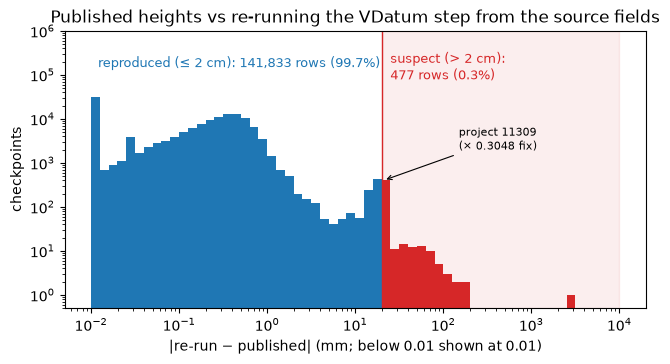

In [11]:
GRID = {"GEOID03": "us_noaa_geoid03_conus.tif", "GEOID09": "us_noaa_geoid09_conus.tif",
        "GEOID12A": "us_noaa_g2012bu0.tif", "GEOID12B": "us_noaa_g2012bu0.tif", "GEOID18": "us_noaa_g2018u0.tif"}
UNIT = {"meter": 1.0, "U.S. Survey Feet": 1200 / 3937, "International Feet": FT}

def geoid(grid, lat, lon):
    """Geoid undulation (m) from an NGS grid via PROJ."""
    t = pyproj.Transformer.from_pipeline(
        "+proj=pipeline +step +proj=axisswap +order=2,1 +step +proj=unitconvert +xy_in=deg +xy_out=rad "
        f"+step +proj=vgridshift +grids={grid} +multiplier=1 +step +proj=unitconvert +xy_in=rad +xy_out=deg "
        "+step +proj=axisswap +order=2,1")
    return t.transform(lat, lon, np.zeros(len(lat)))[2]

x, y = allcp.geometry.x.values, allcp.geometry.y.values
v = allcp[(x > -125) & (x < -66) & (y > 24) & (y < 50) & (allcp.source_geoid != "UNK")].copy()
lat, lon = v.geometry.y.values, v.geometry.x.values
n18 = geoid(GRID["GEOID18"], lat, lon)
v["z_rerun"] = np.nan
for g, s in v.groupby("source_geoid"):
    i = v.index.get_indexer(s.index)
    v.loc[s.index, "z_rerun"] = (s.source_elevation * s.source_vertical_unit.map(UNIT)).values + geoid(GRID[g], lat[i], lon[i]) - n18[i]
v["diff_mm"] = (v.z_rerun - v.z) * 1000
a = v.diff_mm.abs()
print(f"{len(v)} CONUS rows: median |rerun - published| {a.median():.1f} mm, 99% within {a.quantile(.99):.1f} mm; "
      f"{(a > 20).sum()} rows > 2 cm, {(a > 100).sum()} > 10 cm")
fig, ax = plt.subplots(figsize=(7.5, 3.6))
bins = np.logspace(-2, 4, 61)
clipped = np.clip(a, 0.01, 1e4)
ax.hist(clipped[a <= 20], bins=bins, color="tab:blue")
ax.hist(clipped[a > 20], bins=bins, color="tab:red")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(0.5, 1e6)
ax.axvspan(20, 1e4, color="tab:red", alpha=0.08); ax.axvline(20, color="tab:red", lw=1)
ax.text(0.012, 1.5e5, f"reproduced (≤ 2 cm): {(a <= 20).sum():,} rows ({(a <= 20).mean():.1%})", color="tab:blue", fontsize=9)
ax.text(25, 1.5e5, f"suspect (> 2 cm):\n{(a > 20).sum()} rows ({(a > 20).mean():.1%})", color="tab:red", fontsize=9, va="center")
ax.annotate("project 11309\n(× 0.3048 fix)", xy=(21, 400), xytext=(150, 2e3), fontsize=8,
            arrowprops=dict(arrowstyle="->", lw=0.8))
ax.set(xlabel="|re-run − published| (mm; below 0.01 shown at 0.01)", ylabel="checkpoints",
       title="Published heights vs re-running the VDatum step from the source fields")
plt.show()

Most rows match to the millimetre. For the 477 that don't, we sent a sample to NOAA's VDatum
service: VDatum returns the same value as PROJ, so the published heights are the ones that are off.
Two bookkeeping errors account for most of them:

- **Project 11309:** USGS's version history says these heights were corrected by multiplying by
  0.3048 instead of re-running VDatum. Multiplying also shrinks the geoid shift already contained
  in the height (here 31 mm becomes 9 mm), which leaves these heights about 2 cm low.
- **One-row offsets:** in several projects the published height of a point equals the re-run
  height of the *previous* point in the file, as if the heights slipped by one row when the
  converted CSVs were joined back (project 6373 has two such runs).

The table shows one example of each: the published height (`z`), our PROJ re-run (`z_rerun`) and
VDatum's answer (`vdatum`). The next cell tests both explanations on every suspect row.

In [12]:
VD_UNIT = {"meter": "m", "U.S. Survey Feet": "us_ft", "International Feet": "ft"}
def vdatum(r):
    q = dict(s_x=r.geometry.x, s_y=r.geometry.y, s_z=r.source_elevation, region="contiguous",
             s_h_frame="NAD83_2011", s_coor="geo", s_v_frame="NAVD88", s_v_unit=VD_UNIT[r.source_vertical_unit],
             s_v_geoid=r.source_geoid.lower(), t_h_frame="NAD83_2011", t_coor="geo", t_v_frame="NAVD88",
             t_v_unit="m", t_v_geoid="geoid18")
    return float(requests.get("https://vdatum.noaa.gov/vdatumweb/api/convert", params=q, timeout=60).json()["t_z"])

big = v[a > 20]
ex = pd.concat([big[big.project_id == 11309].head(1), big[big.project_id == 6373].head(2)])
ex = ex.assign(vdatum=[vdatum(r) for _, r in ex.iterrows()])
ex[["id", "source_geoid", "source_vertical_unit", "source_elevation", "z", "z_rerun", "vdatum"]].round(3).set_index("id")

,source_geoid,source_vertical_unit,source_elevation,z,z_rerun,vdatum
id,,,,,,
NRCS_Lower_and_MiddleGreenPondRough_11309_156,GEOID09,U.S. Survey Feet,401.080,122.259,122.280,122.280
Olympic_Peninsula_WA_QL_1_LiDAR_6373_94,GEOID12A,meter,121.744,121.869,121.750,121.751
Olympic_Peninsula_WA_QL_1_LiDAR_6373_95,GEOID12A,meter,121.699,121.751,121.705,121.706


In [13]:
FT_US = 1200 / 3937
v["num"] = v.id.str.extract(r"_(\d+)$", expand=False).astype(float)
v["file"] = v.id.str.replace(r"_?\d+$", "", regex=True)
v = v.sort_values(["project_id", "file", "num"])
prev_rerun = v.groupby(["project_id", "file"]).z_rerun.shift(1)
# 11309: VDatum run with feet treated as metres, then the result multiplied by 0.3048
shift_m = v.z_rerun - v.source_elevation * FT_US
times_03048 = 0.3048 * (v.source_elevation + shift_m)
v["cause"] = np.select(
    [(v.project_id == 11309) & ((v.z - times_03048).abs() < 0.01),
     (v.z - prev_rerun).abs() < 0.002],
    ["project 11309: result multiplied by 0.3048", "one-row offset: previous point's height"],
    "unexplained")
sus = v[v.diff_mm.abs() > 20]
print(f"11309: the 0.3048 explanation reproduces {(v[v.project_id == 11309].cause != 'unexplained').sum()} "
      f"of {(v.project_id == 11309).sum()} published heights to 1 cm")
sus.groupby("cause").agg(rows=("id", "size"), projects=("project_id", "nunique"),
                         median_abs_mm=("diff_mm", lambda s: s.abs().median())).round(0)

11309: the 0.3048 explanation reproduces 1130 of 1130 published heights to 1 cm


,rows,projects,median_abs_mm
cause,,,
one-row offset: previous point's height,41,18,50.0
project 11309: result multiplied by 0.3048,389,1,21.0
unexplained,47,14,39.0


**Takeaway.** The published heights are reproducible: re-running VDatum on the source fields
gives the published value within 2 cm for 99.7% of CONUS checkpoints. The 477 that differ by more
than 2 cm fall in three groups:

- **Project 11309 (389 rows): a processing error with an exact explanation.** Scaling by 0.3048
  instead of re-running VDatum reproduces all 1,130 of the project's published heights, so
  recomputing them from the source fields is the fix.
- **One-row offsets (41) and unexplained (47): suspect.** These published heights do not match
  their own source fields, but the project DEMs cannot tell which is closer to the ground (both sit
  about 6 cm from the DEM, its own noise level for good checkpoints). Flag them rather than repair
  them, and leave them out of accuracy work at the 10 cm level.
- **One clear outlier:** NVA-432 of ID_SouthernID_2018 (project 183648) is published 2.95 m below
  its own source height. The source height agrees with the DEM to 0.2 m, so this is a processing
  error in the published value, not a poor measurement.

# Part 3. Source coordinates inconsistent with their recorded coordinate system

*Parts 3 and 4 do not change the heights* (a metre of horizontal error changes the geoid lookup by
well under a millimetre). *They change which ground a height is compared to*: Anyone who samples a
DEM at the published lon,lat position would be sampling it where the checkpoint was not actually surveyed. Part 5
shows what that does on a slope.

Each checkpoint carries the surveyed coordinates (`source_easting`, `source_northing`) and the code
of their coordinate system (`source_horizontal_epsg`). In this test we transform the source coordinates in their recorded projected coordinate system to lon,lat NAD83(2011) and see if they land near the published lon,lat position in the USGS database. 

NOTE: Some codes are Esri codes recorded as EPSG codes, e.g. 102410; they are resolved as Esri codes.

In [14]:
G = pyproj.Geod(ellps="GRS80")
def dist(lon1, lat1, lon2, lat2):
    return G.inv(lon1, lat1, lon2, lat2)[2]

def recorded_crs(code):
    """source_horizontal_epsg as a CRS: an EPSG code, or an Esri code recorded as one."""
    for auth in ("EPSG", "ESRI"):
        try:
            return pyproj.CRS.from_authority(auth, str(int(code))), f"{auth}:{int(code)}"
        except pyproj.exceptions.CRSError:
            pass
    raise ValueError(code)

recs = []
for code, g in allcp.groupby("source_horizontal_epsg"):
    crs, label = recorded_crs(code)
    e, n, px, py = g.source_easting.values, g.source_northing.values, g.geometry.x.values, g.geometry.y.values
    lon_r, lat_r = pyproj.Transformer.from_crs(crs, crs.geodetic_crs, always_xy=True).transform(e, n)
    lon_t, lat_t = pyproj.Transformer.from_crs(crs, "EPSG:6318", always_xy=True).transform(e, n)
    recs.append(pd.DataFrame({"id": g.id.values, "code": label, "crs": crs.name, "datum": crs.geodetic_crs.name,
                              "relabel_m": dist(lon_r, lat_r, px, py), "transform_m": dist(lon_t, lat_t, px, py),
                              "lon_r": lon_r, "lat_r": lat_r}))
h = pd.concat(recs, ignore_index=True)
far, near = h[h.relabel_m >= 1000], h[h.relabel_m < 1000]
print(f"{len(h)} rows: source coordinates within 1 km of the published lon,lat position: {len(near):,}; "
      f"more than 1 km away: {len(far):,}")

145299 rows: source coordinates within 1 km of the published lon,lat position: 140,551; more than 1 km away: 4,748


For the rows more than 1 km away (mostly thousands of kilometres), the published lon,lat
positions agree with the project DEMs (Part 1), so it is the source fields that are wrong. For
each group (one recorded code in one project) we ask which coordinate system the values actually
fit: every NAD83-family projected CRS in the EPSG database whose area of use comes within 3° of the points, with the
axes as recorded and swapped, matching the published lon,lat position to 50 m. Only the projection
is reported (NAD83 realizations differ by less than 2 m, not resolvable at 50 m).

The metadata says the geoid, horizontal EPSG and vertical EPSG were pulled from WESM and compared
with the checkpoints (process steps 10–11), so a recorded code can be the lidar project's
coordinate system rather than the one the checkpoint file was delivered in.

In [15]:
from pyproj.aoi import AreaOfInterest
from pyproj.database import query_crs_info
from pyproj.enums import PJType

far = far.merge(allcp[["id", "project_id", "source_easting", "source_northing", "geometry"]], on="id")
far["fits"] = "no NAD83 projection fits"
for (code, pid), g in far.groupby(["code", "project_id"]):
    e, n = g.source_easting.values, g.source_northing.values
    px, py = np.array([p.x for p in g.geometry]), np.array([p.y for p in g.geometry])
    # widened by 3 deg: values are often in a zone whose area of use stops short of the points
    aoi = AreaOfInterest(px.min() - 3, py.min() - 3, px.max() + 3, py.max() + 3)
    cands = [c for c in query_crs_info(auth_name="EPSG", pj_types=PJType.PROJECTED_CRS, area_of_interest=aoi)
             if c.name.startswith("NAD83") and not c.deprecated]
    best, best_ok = None, np.zeros(len(g), bool)
    for c in cands:
        crs = pyproj.CRS.from_epsg(int(c.code))
        to_geo = pyproj.Transformer.from_crs(crs, crs.geodetic_crs, always_xy=True)
        for swapped, (a, b) in ((False, (e, n)), (True, (n, e))):
            lo, la = to_geo.transform(a, b)
            ok = dist(lo, la, px, py) < 50
            if ok.sum() > best_ok.sum():
                best, best_ok = c.name.split(" / ", 1)[-1] + (", axes swapped" if swapped else ""), ok
    if best:
        far.loc[g.index[best_ok], "fits"] = best
far["recorded"] = far.code + " " + far.crs
print(f"{len(far)} rows; a projection fits {(far.fits != 'no NAD83 projection fits').sum()}")
far.groupby(["recorded", "fits"]).agg(rows=("id", "size"), projects=("project_id", "nunique")
    ).sort_values("rows", ascending=False)

4748 rows; a projection fits 4513


,,rows,projects
recorded,fits,,
EPSG:26916 NAD83 / UTM zone 16N,Kentucky Single Zone (ftUS),1130,1
EPSG:26915 NAD83 / UTM zone 15N,Arkansas North (ftUS),924,3
EPSG:2226 NAD83 / California zone 2 (ftUS),UTM zone 10N,411,1
EPSG:6341 NAD83(2011) / UTM zone 12N,"UTM zone 12N, axes swapped",362,2
EPSG:26914 NAD83 / UTM zone 14N,Kansas South (ftUS),301,1
EPSG:6590 NAD83(2011) / Vermont (ftUS),Vermont,224,2
ESRI:102629 NAD_1983_StatePlane_Alabama_East_FIPS_0101_Feet,Alabama West (ftUS),182,2
EPSG:6345 NAD83(2011) / UTM zone 16N,Florida North,179,1
EPSG:6531 NAD83(2011) / New Mexico East (ftUS),New York East,130,1


The values fit a different projection in most groups: a state plane zone recorded as UTM, the
wrong state or zone, a foot code for metre values (the metre zone fits), or easting and northing
swapped. These rows cannot be re-derived from their source fields as recorded; their published
lon,lat position is the only one available, and they are left out of Part 4.

# Part 4. How the published lon,lat positions were made

For the rows whose source coordinates are consistent with their recorded coordinate system (Part
3), we re-derive the published lon,lat position two ways:

- **re-label**: unproject in the recorded coordinate system's own datum but call the result NAD83(2011)
- **PROJ transform**: PROJ's best transformation from the recorded coordinate system to NAD83(2011) (for NAD83(1986) applies a NADCON5 grid shift, typically 0.2–1 m in CONUS).

Whichever agrees with the published lon,lat position is what we assume was done. The metadata says only that the data were "projected ... to North American Datum of 1983 (2011) geographic (EPSG: 6318)"; the data management plan says the processing was done in Esri ArcGIS Pro, and the transformation
chosen is not recorded.

Both derivations take the recorded datum at its word. A wrong *realization* in the recorded code (NAD83 written for data actually in NAD83(2011)) moves a point by metres, not kilometres, so Part 3 cannot catch it, and nothing in the release can. Part 4 therefore shows how the published lon,lat
positions relate to the source coordinates as labelled, not which label is right.

In [16]:
summary = near.groupby("datum").agg(rows=("id", "size"), relabel_median_mm=("relabel_m", "median"),
                                    transform_median_mm=("transform_m", "median"))
summary[["relabel_median_mm", "transform_median_mm"]] *= 1000
summary.round(0).sort_values("rows", ascending=False)

,rows,relabel_median_mm,transform_median_mm
datum,,,
NAD83(2011),110960,0.0,0.0
NAD83,16874,5.0,286.0
NAD83(HARN),9925,330.0,326.0
NAD83(NSRS2007),1308,5.0,23.0
NAD83(CORS96),1139,264.0,264.0
WGS 84,345,1206.0,1206.0


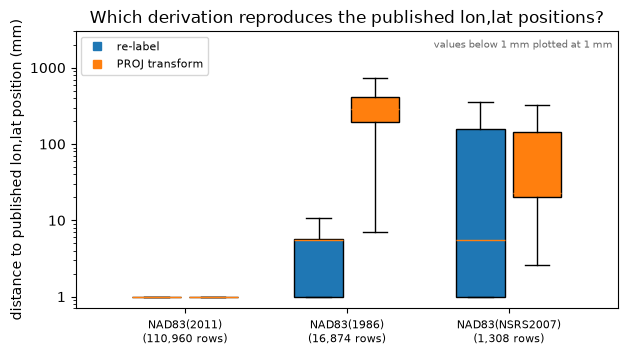

In [17]:
CLEAR = {"NAD83(2011)": "NAD83(2011)", "NAD83": "NAD83(1986)", "NAD83(NSRS2007)": "NAD83(NSRS2007)"}
fig, ax = plt.subplots(figsize=(7, 3.6))
pos = np.arange(len(CLEAR))
for k, (col, lab, color) in enumerate([("relabel_m", "re-label", "tab:blue"), ("transform_m", "PROJ transform", "tab:orange")]):
    data = [np.clip(near.loc[near.datum == d, col] * 1000, 1, None) for d in CLEAR]
    b = ax.boxplot(data, positions=pos + (k - 0.5) * 0.35, widths=0.3, showfliers=False, patch_artist=True)
    for patch in b["boxes"]:
        patch.set_facecolor(color)
    ax.plot([], [], "s", color=color, label=lab)
ax.set_yscale("log"); ax.set_ylim(0.7, 3000)
ax.set_yticks([1, 10, 100, 1000], ["1", "10", "100", "1000"])
ax.set_xticks(pos, [f"{lab}\n({(near.datum == d).sum():,} rows)" for d, lab in CLEAR.items()], fontsize=8)
ax.set(ylabel="distance to published lon,lat position (mm)",
       title="Which derivation reproduces the published lon,lat positions?")
ax.text(0.99, 0.97, "values below 1 mm plotted at 1 mm", transform=ax.transAxes, fontsize=7, color="0.4", ha="right", va="top")
ax.legend(fontsize=8, loc="upper left"); plt.show()

NAD83(2011) sources are exact either way. **NAD83(1986) sources match the re-label to millimetres
and miss the PROJ transformation by decimetres**: their coordinates were unprojected and called
NAD83(2011) without the realization shift. NAD83(NSRS2007) sources mostly do the same (median 5 mm),
though some groups sit decimetres from both derivations.

## 4.1 HARN, CORS96 and WGS 84 sources: mixed

For these sources neither derivation fits as a whole. HARN and CORS96 differ from NAD83(2011) by a
few centimetres, so for them the two derivations land within centimetres of each other; when both
miss by decimetres, something else was done. Split by recorded coordinate system, with a third
derivation for HARN (shift HARN → NAD83(1986) with the NADCON HARN grids, then re-label), and the
derivation that lands within 50 mm:

In [18]:
mixed = near[near.datum.isin(["NAD83(HARN)", "NAD83(CORS96)", "WGS 84"])].copy()
harn = mixed.datum == "NAD83(HARN)"
lon_b, lat_b = pyproj.Transformer.from_crs("EPSG:4152", "EPSG:4269", always_xy=True).transform(
    mixed.loc[harn, "lon_r"].values, mixed.loc[harn, "lat_r"].values)          # HARN -> NAD83(1986)
pub = allcp.set_index("id").loc[mixed.loc[harn, "id"]]
mixed["harn_to_1986_m"] = np.nan
mixed.loc[harn, "harn_to_1986_m"] = dist(lon_b, lat_b, pub.geometry.x.values, pub.geometry.y.values)
tab = mixed.groupby(["datum", "crs"]).agg(rows=("id", "size"), relabel_mm=("relabel_m", "median"),
                                          transform_mm=("transform_m", "median"),
                                          harn_to_1986_then_relabel_mm=("harn_to_1986_m", "median"))
for c in ["relabel_mm", "transform_mm", "harn_to_1986_then_relabel_mm"]:
    tab[c] *= 1000
names = {"relabel_mm": "re-label", "transform_mm": "PROJ transform", "harn_to_1986_then_relabel_mm": "HARN → NAD83(1986), re-label"}
tab["matches (≤ 50 mm)"] = tab[list(names)].apply(
    lambda r: ", ".join(names[c] for c in names if r[c] <= 50) or "none", axis=1)
tab.round(0).sort_values("rows", ascending=False).head(14)

rows  relabel_mm  \
datum         crs                                                         
NAD83(HARN)   NAD83(HARN) / Illinois East (ftUS)       3185       337.0   
              NAD83(HARN) / Illinois West (ftUS)       1910       293.0   
              NAD83(HARN) / UTM zone 14N               1514         6.0   
              NAD83(HARN) / South Carolina (ft)        1299       791.0   
NAD83(CORS96) NAD_1983_CORS96_UTM_Zone_10N             1048       265.0   
NAD83(HARN)   NAD83(HARN) / UTM zone 10N                410         6.0   
              NAD83(HARN) / Florida West (ftUS)         394       640.0   
              NAD83(HARN) / Washington South (ftUS)     392       100.0   
WGS 84        WGS 84 / UTM zone 11N                     312      1206.0   
NAD83(HARN)   NAD83(HARN) / Florida North (ftUS)        309       333.0   
              NAD83(HARN) / New Mexico Central (ftUS)   162      1102.0   
              NAD83(HARN) / Florida East (ftUS)          98       235.0   
              NAD83(HARN) / Ohio South (ftUS)            92       929.0   
NAD83(CORS96) NAD_1983_CORS96_Alaska_Albers              91         5.0   

                                                       transform_mm  \
datum         crs                                                     
NAD83(HARN)   NAD83(HARN) / Illinois East (ftUS)              338.0   
              NAD83(HARN) / Illinois West (ftUS)              293.0   
              NAD83(HARN) / UTM zone 14N                       26.0   
              NAD83(HARN) / South Carolina (ft)               804.0   
NAD83(CORS96) NAD_1983_CORS96_UTM_Zone_10N                    265.0   
NAD83(HARN)   NAD83(HARN) / UTM zone 10N                      135.0   
              NAD83(HARN) / Florida West (ftUS)               624.0   
              NAD83(HARN) / Washington South (ftUS)           220.0   
WGS 84        WGS 84 / UTM zone 11N                          1206.0   
NAD83(HARN)   NAD83(HARN) / Florida North (ftUS)              318.0   
              NAD83(HARN) / New Mexico Central (ftUS)        1116.0   
              NAD83(HARN) / Florida East (ftUS)               274.0   
              NAD83(HARN) / Ohio South (ftUS)                 938.0   
NAD83(CORS96) NAD_1983_CORS96_Alaska_Albers                     5.0   

                                                       harn_to_1986_then_relabel_mm  \
datum         crs                                                                     
NAD83(HARN)   NAD83(HARN) / Illinois East (ftUS)                               41.0   
              NAD83(HARN) / Illinois West (ftUS)                               36.0   
              NAD83(HARN) / UTM zone 14N                                      206.0   
              NAD83(HARN) / South Carolina (ft)                               464.0   
NAD83(CORS96) NAD_1983_CORS96_UTM_Zone_10N                                      NaN   
NAD83(HARN)   NAD83(HARN) / UTM zone 10N                                      457.0   
              NAD83(HARN) / Florida West (ftUS)                               505.0   
              NAD83(HARN) / Washington South (ftUS)                           429.0   
WGS 84        WGS 84 / UTM zone 11N                                             NaN   
NAD83(HARN)   NAD83(HARN) / Florida North (ftUS)                               21.0   
              NAD83(HARN) / New Mexico Central (ftUS)                         997.0   
              NAD83(HARN) / Florida East (ftUS)                                 7.0   
              NAD83(HARN) / Ohio South (ftUS)                                 685.0   
NAD83(CORS96) NAD_1983_CORS96_Alaska_Albers                                     NaN   

                                                                  matches (≤ 50 mm)  
datum         crs                                                                    
NAD83(HARN)   NAD83(HARN) / Illinois East (ftUS)       HARN → NAD83(1986), re-label  
              NAD83(HARN) / Illinois West (ftUS)       HARN → NAD8

Some groups were re-labelled (HARN in UTM zones 14N and 10N; CORS96 in Alaska Albers), some match a
shift from HARN *to NAD83(1986)*, the opposite direction to NAD83(2011) (Illinois, Florida North),
and some match none of these (South Carolina, Florida West, CORS96 UTM zone 10N, WGS 84).

**What this means for users of the positions.** Only the 110,960 rows from NAD83(2011) sources are
unambiguous. For the 29,591 other rows with consistent source fields, the published lon,lat position
and the source coordinates carry different datum labels for the same numbers, typically 0.2–1.2 m
apart. That is negligible for flat non-vegetated checkpoints but not on slopes: **a 0.5 m position
error on a 20% slope is a 10 cm height error**, the size of the QL2 vertical accuracy requirement.

The release metadata states that because "all checkpoints were collected by licensed professional
land surveyors, the horizontal accuracy should be within a couple of centimeters"; that holds for the
source coordiantes, but not for the published lon,lat positions of non-NAD83(2011) sources.

# Part 5. Example: how a lon,lat position error becomes a height error

Checkpoint `South_Platte_River_Flood_LiDAR_6891_91` (NVA, Colorado) was surveyed in NAD83 / UTM
zone 13N, which is also the recorded coordinate system of its project's OPR DEM. Its published lon,lat position is that survey position re-labelled NAD83(2011) (Part 4). A user who takes the NAD83(2011) label at its word and transforms the published lon,lat position into the DEM's coordinate system, as PROJ or any GIS will, applies the NAD83(2011) → NAD83 realization shift (1.0 m here) and samples the DEM 1 m from where the checkpoint was actually surveyed, on a 40% slope.

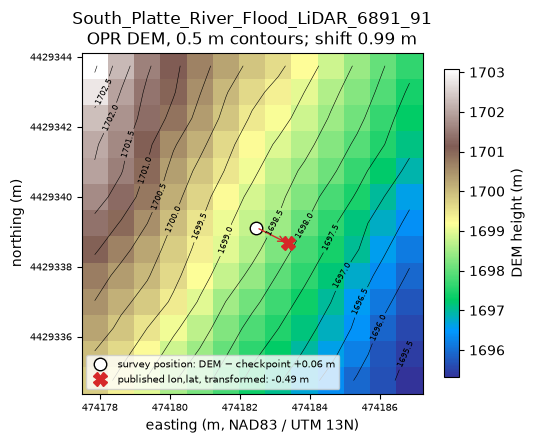

,offset_m,dem_m,checkpoint_m,dem_minus_checkpoint_m
position,,,,
survey (source_easting/northing),0.000,1698.697021,1698.642,0.055
"published lon,lat, transformed",0.995,1698.151978,1698.642,-0.490


In [19]:
from rasterio.windows import from_bounds

ex = allcp[allcp.id == "South_Platte_River_Flood_LiDAR_6891_91"].iloc[0]
VRT = ("/vsicurl/https://prd-tnm.s3.amazonaws.com/StagedProducts/Elevation/OPR/Projects/"
       "South_Platte_River_Flood_LiDAR/CO_SoPlatteRiver-Lot5_2013/CO_SoPlatteRiver_Lot5_2013.vrt")
survey_crs = pyproj.CRS.from_epsg(int(ex.source_horizontal_epsg))          # NAD83 / UTM zone 13N
e_s, n_s = ex.source_easting, ex.source_northing                           # where it was surveyed
e_t, n_t = pyproj.Transformer.from_crs("EPSG:6318", survey_crs, always_xy=True).transform(
    ex.geometry.x, ex.geometry.y)                                          # published lon,lat, transformed

with rasterio.Env(**GDAL), rasterio.open(VRT) as dem:
    assert pyproj.CRS(dem.crs.to_wkt()).equals(survey_crs)                 # DEM and survey share a frame
    h_s, h_t = (next(dem.sample([xy]))[0] for xy in [(e_s, n_s), (e_t, n_t)])
    win = from_bounds(e_s - 5, n_s - 5, e_s + 5, n_s + 5, dem.transform)
    arr, tr = dem.read(1, window=win), dem.window_transform(win)

fig, ax = plt.subplots(figsize=(5.5, 5))
ext = (tr.c, tr.c + tr.a * arr.shape[1], tr.f + tr.e * arr.shape[0], tr.f)
im = ax.imshow(arr, extent=ext, cmap="terrain")
cs = ax.contour(arr, levels=np.arange(np.floor(arr.min()), arr.max(), 0.5), extent=ext, origin="upper", colors="k", linewidths=0.4)
ax.clabel(cs, fontsize=6, fmt="%.1f")
ax.plot(e_s, n_s, "o", ms=9, mfc="w", mec="k", label=f"survey position: DEM − checkpoint {h_s - ex.source_elevation:+.2f} m")
ax.plot(e_t, n_t, "X", ms=10, color="tab:red", label=f"published lon,lat, transformed: {h_t - ex.source_elevation:+.2f} m")
ax.annotate("", xy=(e_t, n_t), xytext=(e_s, n_s), arrowprops=dict(arrowstyle="->", color="tab:red"))
ax.set(xlabel="easting (m, NAD83 / UTM 13N)", ylabel="northing (m)",
       title=f"{ex.id}\nOPR DEM, 0.5 m contours; shift {np.hypot(e_t - e_s, n_t - n_s):.2f} m")
ax.ticklabel_format(useOffset=False, style="plain"); ax.tick_params(labelsize=7)
fig.colorbar(im, ax=ax, label="DEM height (m)", shrink=0.8); ax.legend(fontsize=7, loc="lower left")
plt.show()
pd.DataFrame({"position": ["survey (source_easting/northing)", "published lon,lat, transformed"],
              "offset_m": [0.0, np.hypot(e_t - e_s, n_t - n_s)], "dem_m": [h_s, h_t],
              "checkpoint_m": ex.source_elevation, "dem_minus_checkpoint_m": [h_s - ex.source_elevation, h_t - ex.source_elevation]}
             ).round(3).set_index("position")

At the survey position the DEM sits 5 cm above the checkpoint, typical for a QL2 project. At the incorrectly transformed published lon,lat position it sits 49 cm below, five times the QL2 accuracy requirement. The may seem like a small horizontal error, but on a slope it becomes a large vertical error that would impact accuracy assessments or studies that require cm-scale vertical accuracy.

# Suggested corrections

1. **Unit mislabels and the decimal shift (Part 1: Sonoma, Sacramento, OR_HarneySilver VVA, Fork
   Salt River, ME_SouthernArea).** Only the unit was wrong, so the published VDatum shift stays
   valid: `z_corrected = z_meter_vdatum_update + source_elevation × (true unit − labelled unit)`, in
   metres per unit (ME_SouthernArea: a per-point factor of 10 or 100 as the true unit). After that
   repair, DEM minus checkpoint has a median of −0.03 to +0.05 m in each group.
2. **Oahu (Part 1).** The heights need a datum conversion, not a unit fix; the contractor's
   delivered file already has local-mean-sea-level heights.
3. **Project 11309 (Part 2).** Recompute all 1,130 heights with VDatum from their source fields.
4. **The other 88 suspect heights (Part 2).** Check them against the delivered files; the
   project DEMs cannot tell whether the published or the recomputed height is right.
5. **Source coordinate systems (Part 3).** Correct `source_horizontal_epsg` for the 4,748 rows
   whose coordinates do not fit it (Part 3 finds the projection that fits for most of them), and
   record Esri codes as Esri codes.
6. **Published lon,lat positions from non-NAD83(2011) sources (Part 4).** Confirm each source's
   realization from the delivered files and reports, then apply the transformation to NAD83(2011),
   or label the published lon,lat positions with the realization they are actually in.

# How the groundcontrol parquet handles these findings

[groundcontrol](https://github.com/uw-cryo/groundcontrol) reads this database as a GeoParquet file
(`checkpoints-3dep-2.0-qc.parquet`, built by `scripts/build_checkpoints_3dep.py`). Every USGS
value, including `z_meter_vdatum_update`, the geometry and the `source_*` fields, is kept unchanged.
The findings above are recorded in three added columns: `z_meter_qc` (the height groundcontrol
uses), `qc_height_flag` (heights) and `qc_horizontal_flag` (positions).

| suggested correction | in the parquet | rows |
|---|---|---:|
| 1. unit mislabels, decimal shift | **repaired** in `z_meter_qc`; `qc_height_flag` = `m_labelled_usft`, `m_labelled_ft`, `ft_labelled_m`, `decimal_shift` | 684 |
| 2. Oahu | **blanked**: `z_meter_qc` is NaN; `qc_height_flag` = `ellipsoid_height_labelled_navd88`. The delivered local-mean-sea-level heights are not substituted, since they are not NAVD88 | 100 |
| 3. project 11309 | **recomputed**: `z_meter_qc` is the VDatum re-run (PROJ with the NGS geoid grids); `qc_height_flag` = `vdatum_scaled_not_rerun` | 1,130 |
| 4. the other 88 suspect heights | **flagged only**: `z_meter_qc` keeps the published height; `qc_height_flag` = `vdatum_mismatch` | 88 |
| 5. source coordinate systems | **flagged only**: `qc_horizontal_flag` = `source_crs_mismatch`; the source fields are not used as recorded | 4,748 |
| 6. non-NAD83(2011) sources | **flagged only**: `qc_horizontal_flag` = `source_datum_not_nad83_2011`; geometry is the published lon,lat position, uncertain by 0.2–1.2 m | 29,591 |

Corrections 4–6 need information that is not in the release (the delivered files, the source
realization), so the rows are flagged for users to exclude or down-weight rather than changed.

**This assessment applies to ver. 2.0 only.** The data management plan anticipates annual updates.
The build script is pinned to the MD5 of the ver. 2.0 zip and stops if ScienceBase publishes a
different file, and every rule asserts its row count, so a corrected or extended release cannot pass
through silently. A new release needs this notebook and `scripts/screen_checkpoints_3dep.py` re-run,
and the rules in `scripts/build_checkpoints_3dep.py` revised, before it is published as a new data
release.

Code and full method: `scripts/build_checkpoints_3dep.py`, `scripts/screen_checkpoints_3dep.py` and
`docs/checkpoints_3dep.md` in <https://github.com/uw-cryo/groundcontrol>.

In [20]:
qc = pd.read_parquet("https://s3.kopah.uw.edu/tacolab/groundcontrol/checkpoints-3dep-2.0-qc.parquet",
                     columns=["qc_height_flag", "qc_horizontal_flag"])
pd.crosstab(qc.qc_height_flag.fillna("(none)"), qc.qc_horizontal_flag.fillna("(none)"), margins=True)

qc_horizontal_flag,(none),source_crs_mismatch,source_datum_not_nad83_2011,All
qc_height_flag,,,,
(none),110623,3171,29503,143297
decimal_shift,0,34,0,34
ellipsoid_height_labelled_navd88,100,0,0,100
ft_labelled_m,0,0,39,39
m_labelled_ft,57,0,0,57
m_labelled_usft,143,411,0,554
vdatum_mismatch,37,2,49,88
vdatum_scaled_not_rerun,0,1130,0,1130
All,110960,4748,29591,145299
